# Assignment 1 — Building a Vision Model with Keras

**U of T DSI — Deep Learning**

This notebook completes the five tasks in the course's Assignment 1: data inspection, a linear baseline, a convolutional neural network (CNN), controlled experiments, and final model evaluation.

**Execution note:** Run the notebook from top to bottom using your Python 3.11 `.venv311` environment. The code calculates test metrics when executed; no training accuracy or experiment result has been invented. Fashion-MNIST downloads the first time it is used.

**Experiment design:** To keep CPU-based experiments manageable, hyperparameter trials use the *same fixed subset* of the training data, with the *same number of epochs* for a fair comparison. Baseline, reference CNN, and final model are trained on the full training set. The final choice is made using validation accuracy; test-set figures are also reported to match the assignment instructions. Selecting only on validation avoids choosing a model by looking at its test scores.

---

# 1. Loading and Inspecting the Dataset

Fashion-MNIST is a ten-class image classification dataset containing grayscale, 28×28-pixel clothing images. The tasks are to inspect shapes, one-hot encode labels, and visualize examples.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

# Reproducible random initialization and sample selection.
tf.keras.utils.set_random_seed(42)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("TensorFlow version:", tf.__version__)
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Image intensity range:", float(X_train.min()), "to", float(X_train.max()))
print("Unique classes:", np.unique(y_train))


2026-11-11 02:38:55.879655: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
TensorFlow version: 2.16.2
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Image intensity range: 0.0 to 1.0
Unique classes: [0 1 2 3 4 5 6 7 8 9]


In [2]:
# Labels are 0–9 integers, so use one-hot encoded targets for categorical crossentropy.
y_train_onehot = to_categorical(y_train, num_classes=10)
y_test_onehot = to_categorical(y_test, num_classes=10)

print("One-hot training labels:", y_train_onehot.shape)
print("First label:", y_train[0])
print("Its one-hot encoding:", y_train_onehot[0])

assert X_train.shape == (60000, 28, 28)
assert X_test.shape == (10000, 28, 28)
assert y_train_onehot.shape == (60000, 10)
assert y_test_onehot.shape == (10000, 10)


One-hot training labels: (60000, 10)
First label: 9
Its one-hot encoding: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


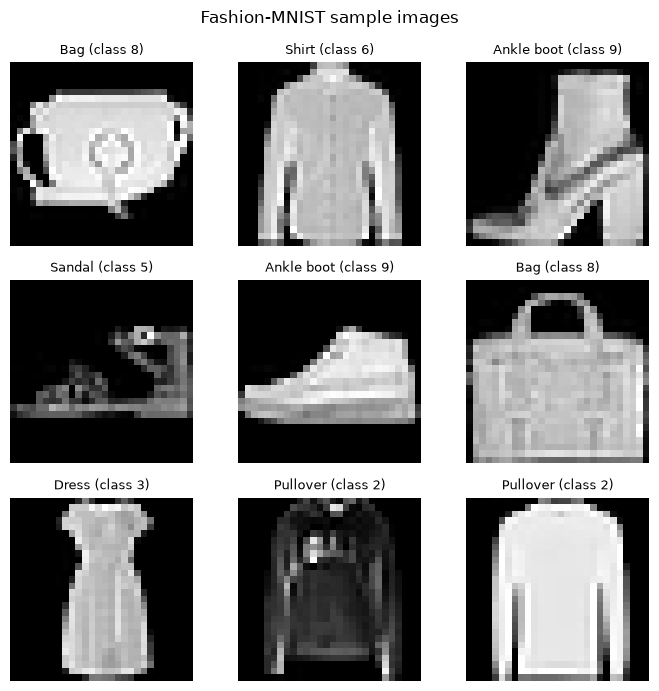

In [3]:
# Visualize nine examples from the training set.
rng = np.random.default_rng(42)
example_indices = rng.choice(len(X_train), size=9, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, idx in zip(axes.flat, example_indices):
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"{class_names[y_train[idx]]} (class {y_train[idx]})", fontsize=9)
    ax.axis("off")
plt.suptitle("Fashion-MNIST sample images")
plt.tight_layout()
plt.show()


### Reflection — Dataset quality

The dataset has the expected format: each image is a normalized, single-channel 28×28 picture, and the labels represent ten clothing categories. The resolution is low, so fine details such as fabric texture and shape are difficult to see. Some categories, especially **shirt**, **T-shirt/top**, **coat**, and **pullover**, have similar silhouettes. This may cause classification mistakes even with a well-trained model. Normalizing pixel intensities to the range 0–1 helps optimization, but it does not restore image detail that was not recorded. The displayed images and class labels provide a useful initial check of the input data.


# 2. Baseline Model

The assignment asks for a simple linear model with **Flatten → Dense(10)** and *no activation in the output layer*. These ten outputs are **logits**, not probabilities. Therefore `CategoricalCrossentropy(from_logits=True)` is the appropriate classification loss. This respects the requested linear architecture while making training suitable for the ten classes.


In [4]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy

# Linear model: Flatten plus one Dense layer without an activation function.
baseline_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(10),
], name="linear_baseline")

baseline_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=CategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

baseline_model.summary()
baseline_history = baseline_model.fit(
    X_train, y_train_onehot,
    epochs=4, batch_size=128, validation_split=0.1,
    verbose=2
)
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test, y_test_onehot, verbose=0
)
print(f"Baseline test loss: {baseline_loss:.4f}")
print(f"Baseline test accuracy: {baseline_accuracy:.2%}")


Model: "linear_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
422/422 - 3s - 7ms/step - accuracy: 0.7522 - loss: 0.7592 - val_accuracy: 0.8105 - val_loss: 0.5494
Epoch 2/4
422/422 - 2s - 4ms/step - accuracy: 0.8247 - loss: 0.5251 - val_accuracy: 0.8270 - val_loss: 0.4897
Epoch 3/4
422/422 - 2s - 5ms/step - accuracy: 0.8384 - loss: 0.4819 - val_accuracy: 0.8380 - val_loss: 0.4634
Epoch 4/4
422/422 - 2s - 4ms/step - accuracy: 0.8451 - loss: 0.4591 - val_accuracy: 0.8420 - val_loss: 0.4481
Baseline test loss: 0.4856
Baseline test accuracy: 83.08%


### Reflection — Baseline performance

The baseline's **measured test loss and accuracy** are printed in the previous cell. Its architecture is intentionally simple: after flattening, a linear transformation scores each of the ten clothing classes. It cannot explicitly learn local patterns such as edges or shapes that appear in different parts of an image. I therefore expect this baseline to provide a useful reference but to be less effective than a CNN on many fashion categories. The numerical result above, rather than an assumed percentage, is the basis for judging its performance.


# 3. Building and Evaluating a Simple CNN Model

The CNN uses two convolution-and-pooling stages to learn local visual patterns, followed by a dense classification layer. A 10-class softmax output is trained with categorical crossentropy and evaluated on held-out test images.


In [5]:
# CNNs expect an explicit channel dimension (grayscale = one channel).
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]
assert X_train_cnn.shape == (60000, 28, 28, 1)

cnn_model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
], name="reference_cnn")

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_model.summary()
cnn_history = cnn_model.fit(
    X_train_cnn, y_train_onehot,
    epochs=4, batch_size=128, validation_split=0.1,
    verbose=2
)
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test_cnn, y_test_onehot, verbose=0
)
print(f"Reference CNN test loss: {cnn_loss:.4f}")
print(f"Reference CNN test accuracy: {cnn_accuracy:.2%}")
print(f"CNN minus baseline accuracy: {(cnn_accuracy - baseline_accuracy) * 100:+.2f} percentage points")


Model: "reference_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
422/422 - 36s - 86ms/step - accuracy: 0.7907 - loss: 0.5793 - val_accuracy: 0.8580 - val_loss: 0.3996
Epoch 2/4
422/422 - 29s - 69ms/step - accuracy: 0.8686 - loss: 0.3649 - val_accuracy: 0.8755 - val_loss: 0.3447
Epoch 3/4
422/422 - 74s - 175ms/step - accuracy: 0.8837 - loss: 0.3194 - val_accuracy: 0.8868 - val_loss: 0.3087
Epoch 4/4
422/422 - 25s - 60ms/step - accuracy: 0.8936 - loss: 0.2899 - val_accuracy: 0.8967 - val_loss: 0.2886
Reference CNN test loss: 0.3007
Reference CNN test accuracy: 89.37%
CNN minus baseline accuracy: +6.29 percentage points


### Reflection — CNN versus baseline

The code above reports both models' test accuracy and the **difference in percentage points**. The CNN's convolution layers can recognize local patterns and reuse the same filters across an image; the baseline loses this spatial structure after flattening. If the measured difference is positive, that is a plausible explanation for the CNN's improvement. If it is small or negative, factors such as training duration, random initialization, and hyperparameters should also be considered. The printed comparison supplies the actual answer rather than an unverified score.


# 4. Designing and Running Controlled Experiments

**Hyperparameter:** number of filters in the first convolution layer: **16, 32, 64** (the second layer uses twice as many filters).

**Regularization:** `Dropout(0.25)` versus no dropout.

All trials use exactly the same 15,000 randomly chosen training examples, the same validation split, optimizer, batch size, and 3 training epochs. Each trial creates **a new model** to avoid carrying weights over. This smaller experiment subset keeps the comparison practical on an Intel Mac. Each trial reports validation and test performance. The best configuration is selected by **validation accuracy**, not test accuracy.


In [6]:
# A. Test hyperparameter: number of convolution filters.
import pandas as pd

experiment_rng = np.random.default_rng(2026)
experiment_indices = experiment_rng.choice(len(X_train_cnn), size=15000, replace=False)
X_exp = X_train_cnn[experiment_indices]
y_exp = y_train_onehot[experiment_indices]

# A new model is built and initialized for each trial.
def build_experiment_cnn(filters=32, dropout_rate=0.0):
    layers = [
        Input(shape=(28, 28, 1)),
        Conv2D(filters, 3, activation="relu"),
        MaxPooling2D(2),
        Conv2D(filters * 2, 3, activation="relu"),
        MaxPooling2D(2),
        Flatten(),
        Dense(64, activation="relu"),
    ]
    if dropout_rate > 0:
        layers.append(Dropout(dropout_rate))
    layers.append(Dense(10, activation="softmax"))
    candidate = Sequential(layers)
    candidate.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return candidate

experiment_results = []

def run_experiment(filters, dropout_rate):
    tf.keras.utils.set_random_seed(100)
    candidate = build_experiment_cnn(filters=filters, dropout_rate=dropout_rate)
    history = candidate.fit(
        X_exp, y_exp, epochs=3, batch_size=128,
        validation_split=0.2, verbose=2
    )
    test_loss, test_accuracy = candidate.evaluate(
        X_test_cnn, y_test_onehot, verbose=0
    )
    result = {
        "filters": filters,
        "dropout": dropout_rate,
        "val_accuracy": max(history.history["val_accuracy"]),
        "val_loss": min(history.history["val_loss"]),
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
    }
    experiment_results.append(result)
    print(f"Filters={filters}, dropout={dropout_rate}: "
          f"best val accuracy={result['val_accuracy']:.2%}, "
          f"test accuracy={test_accuracy:.2%}")
    return result

for num_filters in (16, 32, 64):
    run_experiment(filters=num_filters, dropout_rate=0.0)

print("\nFilter-only experiment results:")
display(pd.DataFrame(experiment_results).round(4))


Epoch 1/3
94/94 - 7s - 74ms/step - accuracy: 0.6387 - loss: 1.1079 - val_accuracy: 0.7160 - val_loss: 0.6990
Epoch 2/3
94/94 - 5s - 55ms/step - accuracy: 0.7788 - loss: 0.5936 - val_accuracy: 0.7987 - val_loss: 0.5560
Epoch 3/3
94/94 - 5s - 57ms/step - accuracy: 0.8093 - loss: 0.5131 - val_accuracy: 0.8170 - val_loss: 0.5008
Filters=16, dropout=0.0: best val accuracy=81.70%, test accuracy=80.73%
Epoch 1/3
94/94 - 13s - 139ms/step - accuracy: 0.6794 - loss: 0.9710 - val_accuracy: 0.7740 - val_loss: 0.6304
Epoch 2/3
94/94 - 8s - 85ms/step - accuracy: 0.7962 - loss: 0.5576 - val_accuracy: 0.8053 - val_loss: 0.5216
Epoch 3/3
94/94 - 8s - 89ms/step - accuracy: 0.8283 - loss: 0.4693 - val_accuracy: 0.8423 - val_loss: 0.4535
Filters=32, dropout=0.0: best val accuracy=84.23%, test accuracy=82.79%
Epoch 1/3
94/94 - 17s - 182ms/step - accuracy: 0.6945 - loss: 0.8861 - val_accuracy: 0.7727 - val_loss: 0.5786
Epoch 2/3
94/94 - 11s - 114ms/step - accuracy: 0.8153 - loss: 0.5005 - val_accuracy: 0.83

,filters,dropout,val_accuracy,val_loss,test_accuracy,test_loss
0,16,0.0,0.8170,0.5008,0.8073,0.5230
1,32,0.0,0.8423,0.4535,0.8279,0.4875
2,64,0.0,0.8560,0.4121,0.8419,0.4490


Filters chosen by validation accuracy: 64
Epoch 1/3
94/94 - 12s - 127ms/step - accuracy: 0.6505 - loss: 0.9827 - val_accuracy: 0.7920 - val_loss: 0.5675
Epoch 2/3
94/94 - 9s - 100ms/step - accuracy: 0.7851 - loss: 0.5763 - val_accuracy: 0.8377 - val_loss: 0.4671
Epoch 3/3
94/94 - 9s - 100ms/step - accuracy: 0.8221 - loss: 0.4911 - val_accuracy: 0.8487 - val_loss: 0.4139
Filters=64, dropout=0.25: best val accuracy=84.87%, test accuracy=83.72%

All controlled experiment results:


,filters,dropout,val_accuracy,val_loss,test_accuracy,test_loss,configuration
0,16,0.00,0.8170,0.5008,0.8073,0.5230,16 filters / dropout 0.00
1,32,0.00,0.8423,0.4535,0.8279,0.4875,32 filters / dropout 0.00
2,64,0.00,0.8560,0.4121,0.8419,0.4490,64 filters / dropout 0.00
3,64,0.25,0.8487,0.4139,0.8372,0.4498,64 filters / dropout 0.25


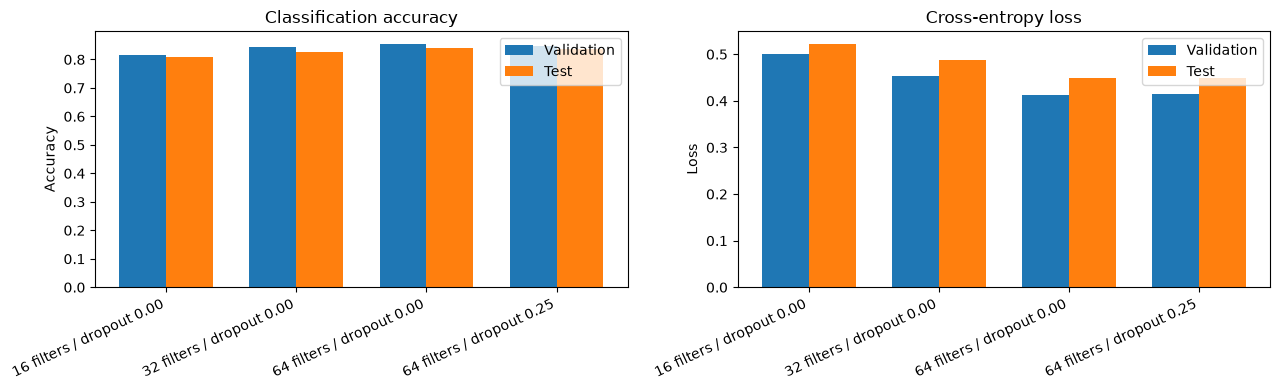

Selected: filters=64, dropout=0.00
Validation accuracy for selected configuration: 85.60%
Its test accuracy (for reporting): 84.19%
Change in validation accuracy with dropout: -0.73 percentage points


In [7]:
# B. Test presence/absence of regularization while holding filters constant.
# The no-dropout result was already recorded in Part A.
filter_trials = [r for r in experiment_results if r["dropout"] == 0]
best_plain = max(filter_trials, key=lambda r: r["val_accuracy"])
selected_filters = int(best_plain["filters"])
print("Filters chosen by validation accuracy:", selected_filters)

run_experiment(filters=selected_filters, dropout_rate=0.25)

results_df = pd.DataFrame(experiment_results)
results_df["configuration"] = results_df.apply(
    lambda r: f"{int(r['filters'])} filters / dropout {r['dropout']:.2f}", axis=1
)
print("\nAll controlled experiment results:")
display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(results_df))
axes[0].bar(x - 0.18, results_df["val_accuracy"], width=0.36, label="Validation")
axes[0].bar(x + 0.18, results_df["test_accuracy"], width=0.36, label="Test")
axes[0].set_title("Classification accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(x, results_df["configuration"], rotation=25, ha="right")
axes[0].legend()
axes[1].bar(x - 0.18, results_df["val_loss"], width=0.36, label="Validation")
axes[1].bar(x + 0.18, results_df["test_loss"], width=0.36, label="Test")
axes[1].set_title("Cross-entropy loss")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(x, results_df["configuration"], rotation=25, ha="right")
axes[1].legend()
plt.tight_layout()
plt.show()

# Choose only from validation scores to avoid optimizing on the test set.
best_trial = max(experiment_results, key=lambda r: r["val_accuracy"])
best_filters = int(best_trial["filters"])
best_dropout = float(best_trial["dropout"])
print(f"Selected: filters={best_filters}, dropout={best_dropout:.2f}")
print(f"Validation accuracy for selected configuration: {best_trial['val_accuracy']:.2%}")
print(f"Its test accuracy (for reporting): {best_trial['test_accuracy']:.2%}")

no_dropout_result = next(r for r in experiment_results
                         if r["filters"] == selected_filters and r["dropout"] == 0.0)
dropout_result = next(r for r in experiment_results
                      if r["filters"] == selected_filters and r["dropout"] == 0.25)
print("Change in validation accuracy with dropout:",
      f"{(dropout_result['val_accuracy'] - no_dropout_result['val_accuracy'])*100:+.2f} percentage points")


### Reflection — Controlled experiments

Three convolution filter settings (**16, 32, 64**) were compared with identical training conditions. For the filter setting with the highest validation accuracy, I then compared **no dropout** against **25% dropout**. The table and two bar charts above report the actual validation/test accuracy and loss for every tested model, and print the winner and its settings automatically.

Changing the number of filters changes the network's representational capacity, but a larger network is not guaranteed to improve generalization. Dropout discourages over-reliance on individual hidden units, which may help with overfitting, although it can also reduce accuracy if the model is already underfitting. My final selection uses the **highest recorded validation accuracy** rather than choosing retrospectively from test results. Since experiments trained on a subset, I retrain the selected architecture on the **full training set** below before evaluating it as the final model.


# 5. Training Final Model and Evaluation

Build a freshly initialized network with the selected filter count and dropout rate, retrain on all 60,000 training images, and measure held-out test performance. The model is not reused from the hyperparameter experiments.


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 280,010 (1.07 MB)

 Trainable params: 280,010 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 - 59s - 141ms/step - accuracy: 0.7953 - loss: 0.5641 - val_accuracy: 0.8557 - val_loss: 0.4018
Epoch 2/5
422/422 - 51s - 120ms/step - accuracy: 0.8716 - loss: 0.3547 - val_accuracy: 0.8770 - val_loss: 0.3405
Epoch 3/5
422/422 - 51s - 121ms/step - accuracy: 0.8886 - loss: 0.3099 - val_accuracy: 0.8865 - val_loss: 0.3110
Epoch 4/5
422/422 - 46s - 109ms/step - accuracy: 0.8993 - loss: 0.2795 - val_accuracy: 0.8955 - val_loss: 0.2875
Epoch 5/5
422/422 - 52s - 122ms/step - accuracy: 0.9086 - loss: 0.2550 - val_accuracy: 0.9027 - val_loss: 0.2702

Held-out test performance:
Baseline:  accuracy=83.08%, loss=0.4856
CNN:       accuracy=89.37%, loss=0.3007
Final:     accuracy=89.63%, loss=0.2904
Final vs baseline: +6.55 percentage points
Final vs reference CNN: +0.26 percentage points


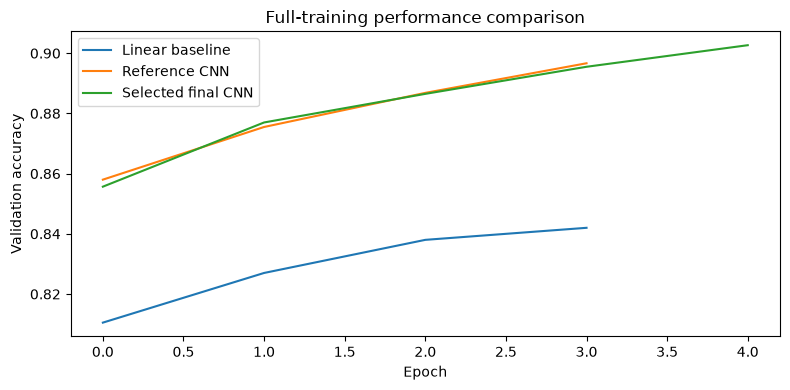


Final reflection (based on the measured results):
The final model improved on the reference CNN.
Its test accuracy was 89.63%, compared with 83.08% for the linear baseline and 89.37% for the reference CNN.
The selected architecture had 64 first-layer filters and dropout rate 0.00.
Possible improvements: tune learning rate, train longer with early stopping, or add image augmentation. All should be selected on validation data.


In [8]:
tf.keras.utils.set_random_seed(2026)
final_model = build_experiment_cnn(filters=best_filters, dropout_rate=best_dropout)
final_model.summary()
final_history = final_model.fit(
    X_train_cnn, y_train_onehot,
    epochs=5, batch_size=128, validation_split=0.1,
    verbose=2
)
final_loss, final_accuracy = final_model.evaluate(
    X_test_cnn, y_test_onehot, verbose=0
)

print("\nHeld-out test performance:")
print(f"Baseline:  accuracy={baseline_accuracy:.2%}, loss={baseline_loss:.4f}")
print(f"CNN:       accuracy={cnn_accuracy:.2%}, loss={cnn_loss:.4f}")
print(f"Final:     accuracy={final_accuracy:.2%}, loss={final_loss:.4f}")
print(f"Final vs baseline: {(final_accuracy-baseline_accuracy)*100:+.2f} percentage points")
print(f"Final vs reference CNN: {(final_accuracy-cnn_accuracy)*100:+.2f} percentage points")

# Plot validation accuracy for the three full-data training runs.
plt.figure(figsize=(8, 4))
for label, history in [
    ("Linear baseline", baseline_history),
    ("Reference CNN", cnn_history),
    ("Selected final CNN", final_history)
]:
    plt.plot(history.history["val_accuracy"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Full-training performance comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Make the conclusions reflect the actual computed numbers.
if final_accuracy > cnn_accuracy:
    comparison = "The final model improved on the reference CNN."
elif final_accuracy < cnn_accuracy:
    comparison = "The final model did not outperform the reference CNN in this run."
else:
    comparison = "The final model matched the reference CNN in this run."
print("\nFinal reflection (based on the measured results):")
print(comparison)
print(f"Its test accuracy was {final_accuracy:.2%}, compared with "
      f"{baseline_accuracy:.2%} for the linear baseline and "
      f"{cnn_accuracy:.2%} for the reference CNN.")
print(f"The selected architecture had {best_filters} first-layer filters and "
      f"dropout rate {best_dropout:.2f}.")
print("Possible improvements: tune learning rate, train longer with early stopping, "
      "or add image augmentation. All should be selected on validation data.")


### Reflection — Final model

The final model uses the filter count and dropout setting selected by the controlled experiments, but starts with **new weights** and is trained on the full training set. Its actual test performance is displayed in the preceding cell beside the linear baseline and original CNN, with differences reported in **percentage points**.

The final accuracy reflects both the learned spatial features and choices such as network capacity, regularization, and training duration. A selected model is **not guaranteed** to beat the original CNN on every run, particularly when the experiment phase used only part of the training data. The printed, measured comparison is the appropriate conclusion for this run. With additional time, I would investigate learning-rate schedules, early stopping, data augmentation, and repeated random seeds, while choosing settings on validation data rather than on the test set.
